# UrbanPulse Nepal — Temporal Pattern Analysis

This notebook describes when incidents in the retrieved BIPAD snapshot were recorded. It examines year-by-year and month-by-month counts, season groupings, and hazard-ID distributions. Calendar features are for historical description only. Counts can reflect reporting coverage and administrative practices as well as real incidents; they are not population-adjusted rates or forecasts.

Run notebooks 01 and 02 first. This notebook reads the processed snapshot, highlights partial years and months with no records, and saves temporal summary tables for later reporting and dashboard work.

## 1. Load incident dates and preserve the coverage caveat

Dates are interpreted in Nepal time. The first and last observed calendar years are partial by construction; 2026 coverage in this snapshot ends on October 13. A month with no records is reported as an empty observed month, not as proof that no disaster occurred.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT=Path.cwd()
if not (PROJECT_ROOT/'data').is_dir(): PROJECT_ROOT=PROJECT_ROOT.parent
if not (PROJECT_ROOT/'data').is_dir(): raise FileNotFoundError('Run from repository or notebooks/ folder.')
DATA_ROOT=PROJECT_ROOT/'data'/'processed'/'bipad_incidents'
data_dirs=sorted((p for p in DATA_ROOT.iterdir() if (p/'incidents_processed.csv').is_file() and (p/'data_quality_report.json').is_file()),key=lambda p:p.name)
if not data_dirs: raise FileNotFoundError('Run notebooks 01 and 02 first.')
DATA_DIR=data_dirs[-1]
df=pd.read_csv(DATA_DIR/'incidents_processed.csv',low_memory=False)
quality=json.loads((DATA_DIR/'data_quality_report.json').read_text(encoding='utf-8'))
df['incident_datetime']=pd.to_datetime(df['incidentOn_nepal'],errors='coerce',utc=True).dt.tz_convert('Asia/Kathmandu')
df=df.dropna(subset=['incident_datetime']).copy()
df['incident_month_period']=df['incident_datetime'].dt.to_period('M')
df['incident_year']=df['incident_datetime'].dt.year.astype(int)
df['month_number']=df['incident_datetime'].dt.month.astype(int)
df['hazard_id']=df['hazard_id'].fillna('unknown').astype('string')
if 'incident_season' not in df.columns: raise ValueError('Run notebook 02 with seasonal feature creation first.')
print('Snapshot:',DATA_DIR.name)
print('Valid incident dates:',f'{len(df):,}')
print('Observed period:',df['incident_datetime'].min().isoformat(),'to',df['incident_datetime'].max().isoformat())
print('Source pagination complete:',quality.get('quality_audit',{}).get('pagination_complete'))

Snapshot: 20261013T101245Z
Valid incident dates: 64,735
Observed period: 2011-04-14T00:00:00+05:45 to 2026-10-13T00:00:00+05:45
Source pagination complete: False


C:\Users\chali\AppData\Local\Temp\ipykernel_42824\679731510.py:19: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['incident_month_period']=df['incident_datetime'].dt.to_period('M')


## 2. Summarize annual and monthly record counts

Year totals are useful for describing the snapshot, but must be read with the partial-year flags and the unverified historical coverage. The 12-month rolling mean below smooths the reported monthly counts; it is not a statistical trend estimate and does not adjust for exposure or data-collection changes.

Annual records:


,incident_year,incident_records,coverage_note
0,2011,1172,First observed year may be partial
1,2012,1717,Full calendar year in date range
2,2013,1692,Full calendar year in date range
3,2014,1352,Full calendar year in date range
4,2015,993,Full calendar year in date range
5,2016,2427,Full calendar year in date range
6,2017,2453,Full calendar year in date range
7,2018,4361,Full calendar year in date range
8,2019,4539,Full calendar year in date range
9,2020,3768,Full calendar year in date range


Number of zero-record months within observed date span: 0


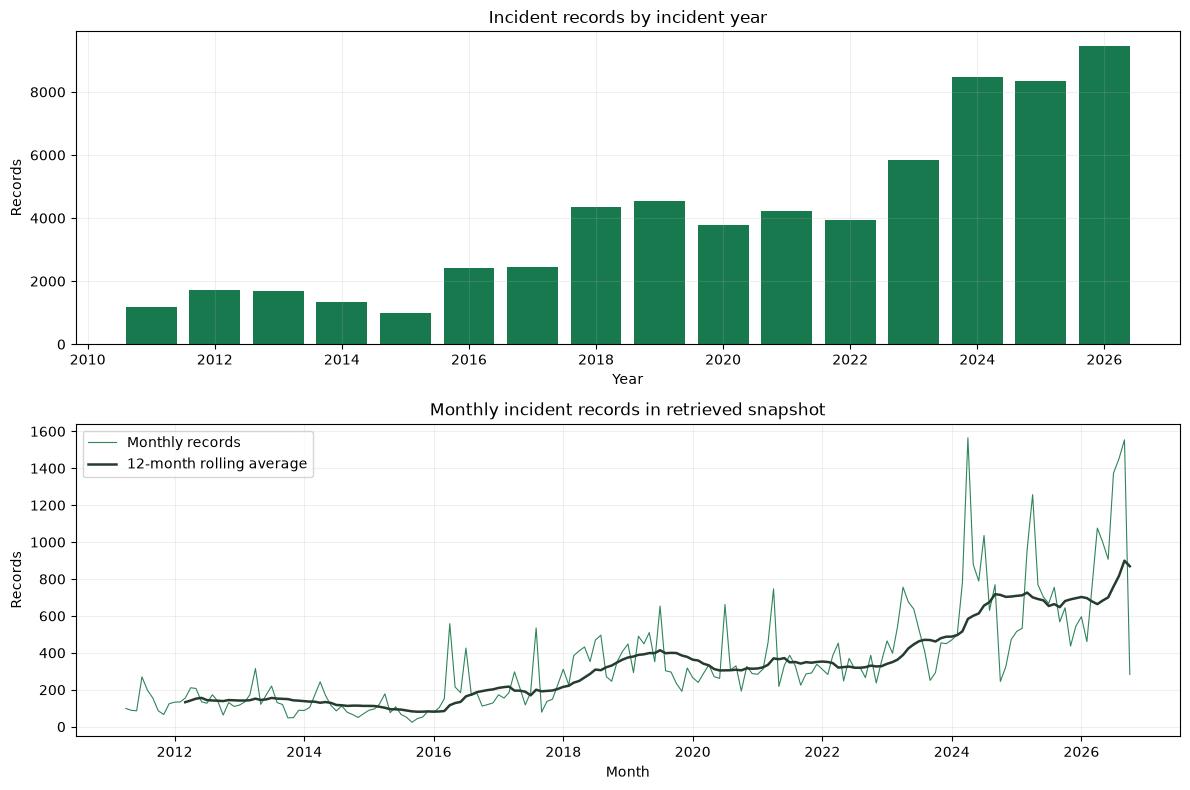

In [2]:
yearly=df.groupby('incident_year').size().rename('incident_records').reset_index()
yearly['coverage_note']='Full calendar year in date range'
yearly.loc[yearly['incident_year']==df['incident_year'].min(),'coverage_note']='First observed year may be partial'
yearly.loc[yearly['incident_year']==df['incident_year'].max(),'coverage_note']='Last observed year is partial'
monthly=df.groupby('incident_month_period').size().rename('incident_records').to_frame()
full_months=pd.period_range(monthly.index.min(),monthly.index.max(),freq='M')
monthly=monthly.reindex(full_months,fill_value=0).rename_axis('month').reset_index()
monthly['month_start']=monthly['month'].dt.to_timestamp()
monthly['rolling_12_month_average']=monthly['incident_records'].rolling(12,min_periods=12).mean()
monthly['no_records_in_snapshot']=(monthly['incident_records']==0)
missing_months=monthly.loc[monthly['no_records_in_snapshot'],'month'].astype(str).tolist()
print('Annual records:'); display(yearly)
print('Number of zero-record months within observed date span:',len(missing_months))
if missing_months: print('Zero-record month examples:',missing_months[:20])
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=False)
axes[0].bar(yearly['incident_year'],yearly['incident_records'],color='#18794e')
axes[0].set(title='Incident records by incident year',xlabel='Year',ylabel='Records')
axes[1].plot(monthly['month_start'],monthly['incident_records'],linewidth=0.8,label='Monthly records',color='#2f855a')
axes[1].plot(monthly['month_start'],monthly['rolling_12_month_average'],linewidth=1.8,label='12-month rolling average',color='#253c2f')
axes[1].set(title='Monthly incident records in retrieved snapshot',xlabel='Month',ylabel='Records'); axes[1].legend()
for ax in axes: ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 3. Compare seasonal and within-year patterns

The notebook uses the season labels derived in notebook 02: Winter (December–February), Pre-monsoon (March–May), Monsoon (June–September), and Post-monsoon (October–November). A simple month-of-year count sums across all observed years and can over-represent years with better coverage or more recorded incidents.

,incident_season,incident_records,share_of_records
0,Winter,12326,0.190407
1,Pre-monsoon,21034,0.324925
2,Monsoon,19469,0.300749
3,Post-monsoon,11906,0.183919


,month_number,incident_records,month_name
0,1,4345,Jan
1,2,3973,Feb
2,3,5992,Mar
3,4,8950,Apr
4,5,6092,May
5,6,5624,Jun
6,7,7470,Jul
7,8,6375,Aug
8,9,5304,Sep
9,10,3367,Oct


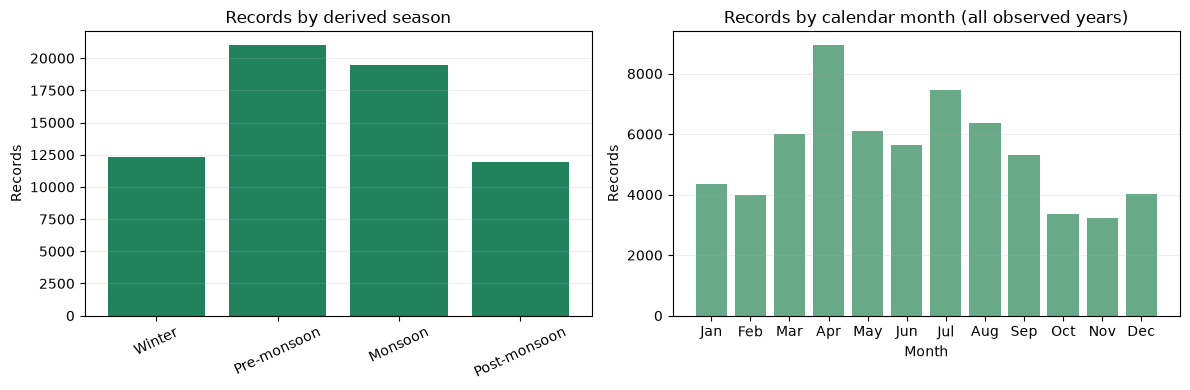

In [3]:
season_order=['Winter','Pre-monsoon','Monsoon','Post-monsoon']
seasonal=df.groupby('incident_season',dropna=False).size().reindex(season_order,fill_value=0).rename('incident_records').reset_index()
seasonal['share_of_records']=seasonal['incident_records']/len(df)
month_of_year=df.groupby('month_number').size().reindex(range(1,13),fill_value=0).rename('incident_records').reset_index()
month_of_year['month_name']=pd.to_datetime(month_of_year['month_number'],format='%m').dt.strftime('%b')
display(seasonal); display(month_of_year)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(seasonal['incident_season'],seasonal['incident_records'],color='#20835d'); axes[0].tick_params(axis='x',rotation=25)
axes[0].set(title='Records by derived season',ylabel='Records')
axes[1].bar(month_of_year['month_name'],month_of_year['incident_records'],color='#68a987')
axes[1].set(title='Records by calendar month (all observed years)',xlabel='Month',ylabel='Records')
for ax in axes: ax.grid(axis='y',alpha=0.2)
plt.tight_layout(); plt.show()

## 4. Inspect temporal patterns by hazard ID

Hazard values remain BIPAD IDs because readable labels have not been joined in the saved incident data. The charts report counts for the most frequent IDs in this snapshot; they should not be interpreted as comparable hazard rates without a verified complete source and appropriate exposure denominators.

hazard_id,10,17,23,14,11,2,12,20
incident_year,,,,,,,,
2017,1492,163,186,95,338,0,0,0
2018,2475,320,244,247,80,141,0,18
2019,2867,449,383,103,206,250,0,42
2020,2129,492,305,360,97,222,7,56
2021,2690,337,207,358,154,310,64,23
2022,2600,327,264,169,55,250,83,25
2023,3759,494,264,174,156,359,276,33
2024,4210,1001,393,558,414,449,960,86
2025,4039,597,432,444,322,541,759,577


incident_season,Winter,Pre-monsoon,Monsoon,Post-monsoon,total_records
hazard_id,,,,,
10,0.298544,0.379075,0.143830,0.178552,34819
17,0.013885,0.053275,0.689858,0.242982,6626
23,0.055783,0.430873,0.359942,0.153402,4159
14,0.003380,0.045352,0.687606,0.263662,3550
11,0.000630,0.055748,0.752441,0.191181,3175
2,0.283465,0.208661,0.286417,0.221457,3048
12,0.119920,0.847410,0.028685,0.003984,2510
20,0.005629,0.098512,0.597507,0.298351,2487
24,0.019983,0.749348,0.193745,0.036924,2302


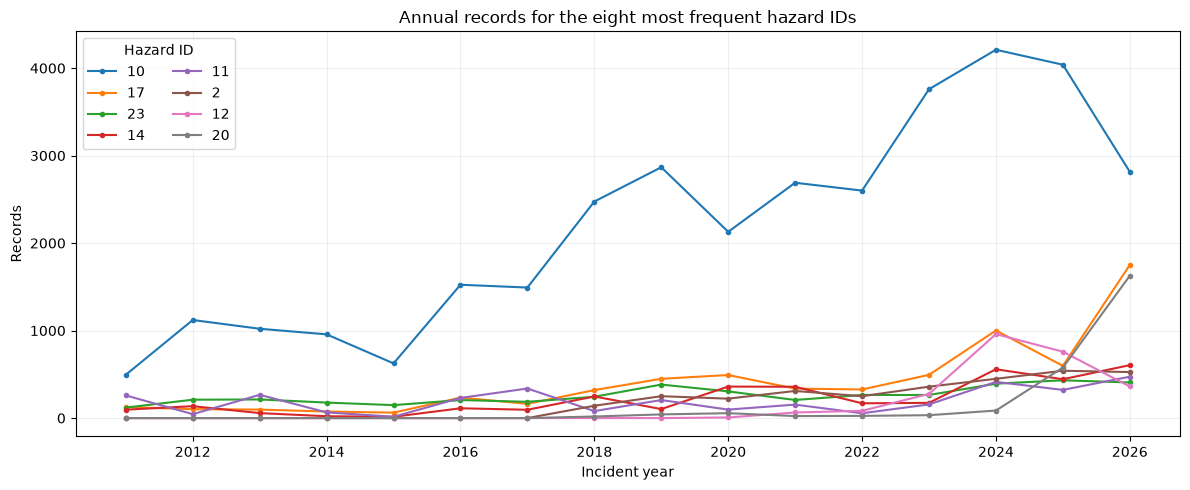

In [4]:
top_hazards=df['hazard_id'].value_counts().head(8).index.tolist()
hazard_year=pd.crosstab(df['incident_year'],df['hazard_id'])
hazard_year=hazard_year.reindex(columns=top_hazards,fill_value=0)
display(hazard_year.tail(10))
hazard_season=pd.crosstab(df['hazard_id'],df['incident_season'],normalize='index').reindex(columns=season_order,fill_value=0)
hazard_season['total_records']=df['hazard_id'].value_counts().reindex(hazard_season.index).values
display(hazard_season.sort_values('total_records',ascending=False).head(12))
ax=hazard_year.plot(kind='line',marker='.',figsize=(12,5))
ax.set(title='Annual records for the eight most frequent hazard IDs',xlabel='Incident year',ylabel='Records'); ax.grid(alpha=0.2); ax.legend(title='Hazard ID',ncol=2)
plt.tight_layout(); plt.show()

## 5. Save temporal summaries and coverage diagnostics

The output tables preserve counts and calendar grouping for later visualization. The coverage report distinguishes observed zero-record months from months outside the first and last incident dates. Because archive completeness is unverified, a zero-record month cannot be confidently interpreted as no disasters having occurred.

In [5]:
OUTPUT_DIR=PROJECT_ROOT/'data'/'processed'/'temporal'/DATA_DIR.name
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
yearly_path=OUTPUT_DIR/'annual_incident_counts.csv'
monthly_path=OUTPUT_DIR/'monthly_incident_counts.csv'
seasonal_path=OUTPUT_DIR/'seasonal_summary.csv'
hazard_year_path=OUTPUT_DIR/'annual_hazard_id_counts.csv'
yearly.to_csv(yearly_path,index=False,encoding='utf-8-sig')
monthly.assign(month=monthly['month'].astype(str)).to_csv(monthly_path,index=False,encoding='utf-8-sig')
seasonal.to_csv(seasonal_path,index=False,encoding='utf-8-sig')
hazard_year.to_csv(hazard_year_path,encoding='utf-8-sig')
temporal_report={'snapshot_id':DATA_DIR.name,'incident_records_with_valid_dates':len(df),'date_min_nepal':df['incident_datetime'].min().isoformat(),'date_max_nepal':df['incident_datetime'].max().isoformat(),'first_observed_year':int(df['incident_year'].min()),'last_observed_year':int(df['incident_year'].max()),'last_year_partial':True,'zero_record_months_inside_observed_date_span':missing_months,'source_pagination_complete':quality.get('quality_audit',{}).get('pagination_complete'),'coverage_limitation':quality.get('coverage_limitation'),'interpretation':'Counts describe this retrieved snapshot, not complete disaster incidence or future risk.'}
report_path=OUTPUT_DIR/'temporal_coverage_report.json'
report_path.write_text(json.dumps(temporal_report,ensure_ascii=False,indent=2),encoding='utf-8')
print('Saved annual counts:',yearly_path)
print('Saved monthly counts:',monthly_path)
print('Saved seasonal summary:',seasonal_path)
print('Saved hazard-year counts:',hazard_year_path)
print('Saved coverage report:',report_path)

Saved annual counts: c:\Projects_Tracking\DisasterLens Nepal\data\processed\temporal\20261013T101245Z\annual_incident_counts.csv
Saved monthly counts: c:\Projects_Tracking\DisasterLens Nepal\data\processed\temporal\20261013T101245Z\monthly_incident_counts.csv
Saved seasonal summary: c:\Projects_Tracking\DisasterLens Nepal\data\processed\temporal\20261013T101245Z\seasonal_summary.csv
Saved hazard-year counts: c:\Projects_Tracking\DisasterLens Nepal\data\processed\temporal\20261013T101245Z\annual_hazard_id_counts.csv
Saved coverage report: c:\Projects_Tracking\DisasterLens Nepal\data\processed\temporal\20261013T101245Z\temporal_coverage_report.json


## Findings from the executed temporal analysis

The saved snapshot contains **64,735 incidents with valid dates**, spanning **2011-04-14 through 2026-10-13** in Nepal time. The first observed year (2011) begins on April 14 and is partial; 2026 is partial through October 13. Annual record totals were 1,172 (2011), 1,717 (2012), 1,692 (2013), 1,352 (2014), 993 (2015), 2,427 (2016), 2,453 (2017), 4,361 (2018), 4,539 (2019), 3,768 (2020), 4,210 (2021), 3,934 (2022), 5,852 (2023), 8,462 (2024), 8,353 (2025), and 9,450 (partial 2026).

Across the four derived season groups, Pre-monsoon accounts for **21,034 records (32.49%)**, Monsoon **19,469 (30.07%)**, Winter **12,326 (19.04%)**, and Post-monsoon **11,906 (18.39%)**. The largest single month in the saved table was **April 2024, with 1,565 records**.

The monthly table contains **187 months** from April 2011 through October 2026, with no zero-record month inside that observed date span. This means at least one record was present for each month; it does not prove that all relevant incidents were reported. October 2026 contains records only through October 13. Hazard trends remain grouped by numeric BIPAD hazard ID because labels were not resolved.

These are counts in this API snapshot, not estimates of changing disaster risk. The source count remains an implausible integer sentinel, pagination completeness is unverified, and year-to-year changes may reflect reporting and source coverage as well as incident patterns.